# ✍️ Практика: перша модель машинного навчання — лінійна регресія

**Самостійна робота · 28 завдань (з них 3 бонусні)**

Ви пройдете весь шлях: від прямої «на око» до моделі в scikit-learn, яка оцінює ціну вживаного авто, і чесної перевірки цієї моделі на нових даних.

| Блок | Тема | Час |
|---|---|---|
| 1 | Основні терміни | 15 хв |
| 2 | Пряма лінія вручну і її помилки | 25 хв |
| 3 | Найкраща пряма за формулою | 15 хв |
| 4 | Лінійна регресія в scikit-learn: одна ознака | 30 хв |
| 5 | Метрики якості | 20 хв |
| 6 | Навчальна і тестова вибірки, перенавчання | 30 хв |
| 7 | Кілька ознак | 30 хв |
| 8 | Підсумковий звіт | 15 хв |

---

### Як працювати з цим блокнотом

1. **Запускайте клітинки по черзі зверху вниз** (Shift + Enter). Спочатку обов'язково запустіть три службові клітинки в розділі «Підготовка».
2. **Пропуски `ВАШ_КОД`** у коді треба замінити на правильний код. Поки пропуск не заповнено, клітинка видасть помилку на кшталт `NameError: name 'ВАШ_КОД' is not defined`, і це нормально. У блоці 1 замініть `'ВАШ_КОД'` на літеру відповіді, наприклад `'б'`.
3. **Підказки відкриваються кліком** на «💡 Підказка 1». Спершу спробуйте самі, потім відкрийте першу підказку. Друга підказка майже містить відповідь, тож користуйтеся нею, якщо зовсім застрягли.
4. **Самоперевірка:** після більшості завдань є клітинка з `check(...)`. Запустіть її, і вона напише ✅ або ❌.
5. **Текстові відповіді:** клітинки «✍️ Ваша відповідь» двічі клацніть і напишіть відповідь своїми словами.
6. Завдання з ⭐ — **бонусні**. Якщо часу мало, їх можна пропустити.
7. Застрягли на завданні більше ніж на 10 хвилин — переходьте до наступного і поверніться пізніше.

> 💡 Відкрити в Google Colab: *File → Upload notebook*. Усі дані генеруються всередині блокнота.

---
## Підготовка

Запустіть три клітинки нижче: бібліотеки, дані та функції самоперевірки.

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.float_format', '{:.2f}'.format)

### Дані

**`ad`, `sales`** — маленький набір для ручних розрахунків: витрати на рекламу (тис. грн) і продажі (шт.) за 8 тижнів.

**`cars`** — 300 вживаних авто на онлайн-майданчику:

| Колонка | Що означає |
|---|---|
| `age_years` | вік авто, років |
| `mileage_th_km` | пробіг, тис. км |
| `engine_l` | об'єм двигуна, л |
| `doors` | кількість дверей |
| `price` | ціна, тис. $ — **цільова змінна** |

In [64]:
# --- 1. Маленький набір: реклама і продажі за 8 тижнів ---
ad = np.array([5, 8, 10, 12, 15, 18, 20, 25])                 # витрати на рекламу, тис. грн
sales = np.array([62, 70, 79, 80, 94, 102, 108, 125])         # продажі, шт.

# --- 2. Основний датасет: вживані авто на онлайн-майданчику ---
rng = np.random.default_rng(31)
n = 300
age = rng.integers(1, 16, n)
mileage = np.round(np.clip(age * 15 + rng.normal(0, 25, n), 5, None))
engine = rng.choice([1.2, 1.4, 1.6, 1.8, 2.0, 2.5, 3.0], n, p=[0.12, 0.2, 0.25, 0.15, 0.15, 0.08, 0.05])
doors = rng.choice([3, 5], n, p=[0.25, 0.75])
price = np.round(np.clip(26 - 0.9 * age - 0.035 * mileage + 4.0 * engine + rng.normal(0, 2.0, n), 1.5, None), 1)

cars = pd.DataFrame({
    'age_years':     age,        # вік авто, років
    'mileage_th_km': mileage,    # пробіг, тис. км
    'engine_l':      engine,     # об'єм двигуна, л
    'doors':         doors,      # кількість дверей
    'price':         price,      # ціна, тис. $  ← цільова змінна
})
print('cars:', cars.shape)
cars.head()

cars: (300, 5)


,age_years,mileage_th_km,engine_l,doors,price
0,9,131.00,1.40,5,17.80
1,14,202.00,2.00,3,16.60
2,8,155.00,1.60,5,22.10
3,2,36.00,1.20,3,30.80
4,9,122.00,2.00,5,20.80


In [65]:
# ⚙️ Службова клітинка: функції для самоперевірки. Просто запустіть її, змінювати нічого не потрібно.
ANSWERS = {
    '1.1': ['б'],
    '1.2': ['р', 'к', 'р', 'к'],
    '1.3': [300.0, 4.0],
    '2.1': [87.0],
    '2.2': [[60.0, 69.0, 75.0, 81.0, 90.0, 99.0, 105.0, 120.0], 2.875],
    '2.3': [2.45, 2.0],
    '2.4': [10.125, 3.181981],
    '3.1': [3.155609, 45.427021],
    '3.2': [1.183353, 2.293426],
    '3.3': [3.155609, 45.427021],
    '4.1': [[300.0, 1.0]],
    '4.2': [-1.422492, 33.016611],
    '4.3': [25.904151, [30.171627, 21.636675, 15.946707]],
    '4.5': [-9.65815],
    '5.1': [2.379265, 2.997093, 0.800412],
    '5.2': [-0.894657, 0.800412],
    '6.1': [240.0, 60.0],
    '6.2': [2.395932, 2.330524],
    '6.3': [0.0, 7.113669],
    '6.4': ['б'],
    '7.1': [[-0.914158, -0.033702, 4.454841]],
    '7.2': [1.469716, 0.939509],
    '7.3': [28.43547],
    '7.5': [0.155824, 1.461395],
}

_LATIN = {'a': 'а', 'b': 'б', 'v': 'в', 'c': 'в', 'p': 'р', 'r': 'р', 'k': 'к'}

def _same(v, e):
    if isinstance(e, str):
        v = str(v).strip().lower()
        v = _LATIN.get(v, v)
        return v == e.lower() or (len(e) == 1 and len(v) > 0 and _LATIN.get(v[0], v[0]) == e.lower())
    if isinstance(e, list):
        try:
            v = np.asarray(v, dtype=float)
            return v.shape == np.asarray(e).shape and np.allclose(v, e, atol=0.01, rtol=0.005)
        except (TypeError, ValueError):
            return False
    try:
        return abs(float(v) - e) <= max(0.005, abs(e) * 0.005)
    except (TypeError, ValueError):
        return False

def check(task, *values):
    expected = ANSWERS[task]
    if len(values) != len(expected):
        print(f'⚠️ Очікую {len(expected)} значення(нь), а отримала функція {len(values)}.')
        return
    if all(_same(v, e) for v, e in zip(values, expected)):
        print(f'✅ Завдання {task}: правильно! Можна рухатися далі.')
    else:
        print(f'❌ Завдання {task}: поки не збігається. Перевірте код і відкрийте підказку.')

---

## Блок 1. Основні терміни (⏱ 15 хв)

Тут не треба писати код — оберіть правильну відповідь і запишіть її в змінну. Автоперевірка підкаже, чи ви праві.

**Нагадування:**

| Термін | Що це |
|---|---|
| **Ознаки (X)** | те, що ми знаємо про об'єкт (стовпці таблиці) |
| **Цільова змінна (y)** | те, що хочемо передбачити |
| **Регресія** | передбачаємо **число** (ціна, кількість, час) |
| **Класифікація** | передбачаємо **категорію** (так/ні, тип, клас) |

### Завдання 1.1. Що є цільовою змінною?

Компанія хоче **оцінювати ціну вживаного авто** за його віком, пробігом і об'ємом двигуна. Що є цільовою змінною y?

- **а)** вік авто
- **б)** ціна авто
- **в)** пробіг авто

<details>
<summary><b>💡 Підказка 1</b></summary>

Цільова змінна — це те, що ми хочемо **передбачити**, тобто те, чого ми не знаємо для нового авто.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Вік, пробіг і об'єм двигуна продавець знає заздалегідь — це ознаки X.

</details>

In [66]:
# answer_1_1 = 'ВАШ_КОД'    # а, б або в
# Цільова змінна — ціна автомобіля,
# тому що саме її ми хочемо передбачити

answer_1_1 = 'б'

In [67]:
check('1.1', answer_1_1)

✅ Завдання 1.1: правильно! Можна рухатися далі.


### Завдання 1.2. Регресія чи класифікація?

Для кожної задачі запишіть **'р'** (регресія) або **'к'** (класифікація):

1. Передбачити, скільки хвилин триватиме доставка.
2. Визначити, чи відпише клієнт від підписки наступного місяця.
3. Спрогнозувати виручку магазину на наступний тиждень.
4. Визначити, чи є транзакція шахрайською.

<details>
<summary><b>💡 Підказка 1</b></summary>

Питання до кожної задачі: відповідь — це **число** чи **одна з кількох категорій** (так/ні)?

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Хвилини й виручка — числа. «Відпише / не відпише», «шахрайська / ні» — категорії.

</details>

In [68]:
# task_1 = 'ВАШ_КОД'
# task_2 = 'ВАШ_КОД'
# task_3 = 'ВАШ_КОД'
# task_4 = 'ВАШ_КОД'

task_1 = 'р'
task_2 = 'к'
task_3 = 'р'
task_4 = 'к'

In [69]:
check('1.2', task_1, task_2, task_3, task_4)

✅ Завдання 1.2: правильно! Можна рухатися далі.


### Завдання 1.3. Скільки об'єктів і ознак?

Подивіться на таблицю `cars`. Скільки в ній **об'єктів** (`n_objects`)? Скільки **ознак**, тобто стовпців без цільової змінної `price` (`n_features`)?

<details>
<summary><b>💡 Підказка 1</b></summary>

`cars.shape` повертає (рядки, стовпці). Рядки — об'єкти. Серед стовпців один — цільова змінна, його не рахуємо.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
n_objects = cars.shape[0]
n_features = cars.shape[1] - 1
```

</details>

In [70]:
# print(cars.shape)
# n_objects = cars.shape[ВАШ_КОД]
# n_features = cars.shape[1] - ВАШ_КОД
# print('Об\'єктів:', n_objects, '| Ознак:', n_features)

print(cars.shape)
n_objects = cars.shape[0]
n_features = cars.shape[1] - 1
print('Об\'єктів:', n_objects, '| Ознак:', n_features)


(300, 5)
Об'єктів: 300 | Ознак: 4


In [71]:
check('1.3', n_objects, n_features)

✅ Завдання 1.3: правильно! Можна рухатися далі.


---

## Блок 2. Пряма лінія вручну і її помилки (⏱ 25 хв)

Працюємо з маленьким набором `ad` (реклама, тис. грн) і `sales` (продажі, шт.) за 8 тижнів.

**Нагадування:**
- Модель-пряма: $\hat{y} = a + b \cdot x$. **b** — на скільки зростає прогноз, якщо x зростає на 1. **a** — прогноз при x = 0.
- **Помилка** = справжнє значення − прогноз: $y - \hat{y}$.
- **MAE** = середнє від |помилок|. **MSE** = середнє від помилок². **RMSE** = √MSE.
- З масивами numpy можна рахувати одразу для всіх елементів: `45 + 3 * ad` дає 8 прогнозів.

### Завдання 2.1. Один прогноз

Менеджер пропонує модель: **продажі = 45 + 3 × реклама**. Скільки продажів вона прогнозує, якщо на рекламу витратити 14 тис. грн? Збережіть у `pred_14`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Підставте x = 14 у формулу.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
pred_14 = 45 + 3 * 14
```

</details>

In [72]:
# pred_14 = ВАШ_КОД + ВАШ_КОД * 14
# print('Прогноз:', pred_14, 'продажів')

pred_14 = 45 + 3 * 14
print('Прогноз:', pred_14, 'продажів')


Прогноз: 87 продажів


In [73]:
check('2.1', pred_14)

✅ Завдання 2.1: правильно! Можна рухатися далі.


### Завдання 2.2. Помилки прямої менеджера

Порахуйте прогнози моделі «45 + 3 × реклама» для **всіх 8 тижнів** (`pred_1`), помилки (`errors_1` = sales − pred_1) і MAE (`mae_1`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Формула з масивом `ad` дає одразу 8 прогнозів. Модуль — `np.abs(...)`, середнє — `.mean()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
pred_1 = 45 + 3 * ad
errors_1 = sales - pred_1
mae_1 = np.abs(errors_1).mean()
```

</details>

In [74]:
# pred_1 = 45 + 3 * ВАШ_КОД
# errors_1 = ВАШ_КОД - pred_1
# mae_1 = np.abs(errors_1).ВАШ_КОД()

# print(pd.DataFrame({'реклама': ad, 'продажі': sales, 'прогноз': pred_1, 'помилка': errors_1}))
# print(f'\nMAE = {mae_1:.2f}')

pred_1 = 45 + 3 * ad
errors_1 = sales - pred_1
mae_1 = np.abs(errors_1).mean()

print(pd.DataFrame({'реклама': ad, 'продажі': sales, 'прогноз': pred_1, 'помилка': errors_1}))
print(f'\nMAE = {mae_1:.2f}')


   реклама  продажі  прогноз  помилка
0        5       62       60        2
1        8       70       69        1
2       10       79       75        4
3       12       80       81       -1
4       15       94       90        4
5       18      102       99        3
6       20      108      105        3
7       25      125      120        5

MAE = 2.88


In [75]:
check('2.2', pred_1, mae_1)

✅ Завдання 2.2: правильно! Можна рухатися далі.


### Завдання 2.3. Чия пряма краща?

Інший менеджер пропонує модель **продажі = 50 + 2.8 × реклама**. Порахуйте її MAE (`mae_2`). Запишіть у `best_line` номер кращої моделі (1 або 2).

<details>
<summary><b>💡 Підказка 1</b></summary>

Повторіть розрахунок із 2.2 для іншої формули. Краща та модель, у якої MAE **менша**.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
pred_2 = 50 + 2.8 * ad
mae_2 = np.abs(sales - pred_2).mean()
best_line = 1 if mae_1 < mae_2 else 2
```

</details>

In [76]:
# pred_2 = ВАШ_КОД
# mae_2 = np.abs(sales - pred_2).mean()
# print(f'MAE моделі 1: {mae_1:.2f} | MAE моделі 2: {mae_2:.2f}')

# best_line = ВАШ_КОД    # 1 або 2

pred_2 = 50 + 2.8 * ad
mae_2 = np.abs(sales - pred_2).mean()
print(f'MAE моделі 1: {mae_1:.2f} | MAE моделі 2: {mae_2:.2f}')

best_line = 1 if mae_1 < mae_2 else 2


MAE моделі 1: 2.88 | MAE моделі 2: 2.45


In [77]:
check('2.3', mae_2, best_line)

✅ Завдання 2.3: правильно! Можна рухатися далі.


### Завдання 2.4. MSE і RMSE

Для моделі 1 порахуйте MSE (`mse_1`) і RMSE (`rmse_1`). Порівняйте RMSE з MAE.

<details>
<summary><b>💡 Підказка 1</b></summary>

MSE — середнє від **квадратів** помилок: `(errors_1 ** 2).mean()`. RMSE — корінь: `np.sqrt(...)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
mse_1 = (errors_1 ** 2).mean()
rmse_1 = np.sqrt(mse_1)
```

</details>

In [78]:
# mse_1 = (errors_1 ** ВАШ_КОД).mean()
# rmse_1 = np.ВАШ_КОД(mse_1)
# print(f'MAE = {mae_1:.2f} | MSE = {mse_1:.2f} | RMSE = {rmse_1:.2f}')

mse_1 = (errors_1 ** 2).mean()
rmse_1 = np.sqrt(mse_1)
print(f'MAE = {mae_1:.2f} | MSE = {mse_1:.2f} | RMSE = {rmse_1:.2f}')


MAE = 2.88 | MSE = 10.12 | RMSE = 3.18


In [79]:
check('2.4', mse_1, rmse_1)

✅ Завдання 2.4: правильно! Можна рухатися далі.


**✍️ Чому RMSE вийшла більшою за MAE? У яких одиницях вимірюються MAE, MSE і RMSE?**

RMSE (3.18) більша за MAE (2.88), тому що RMSE сильніше враховує великі помилки прогнозування завдяки піднесенню помилок до квадрата.

MAE та RMSE вимірюються в тих самих одиницях, що й цільова змінна, а MSE — у квадратних одиницях.

---

## Блок 3. Найкраща пряма за формулою (⏱ 15 хв)

Лінійна регресія шукає пряму з **найменшою сумою квадратів помилок**. Для однієї ознаки є точна формула:

$$b = \frac{\text{cov}(x, y)}{\text{var}(x)}, \qquad a = \bar{y} - b \cdot \bar{x}$$

| Код | Що рахує |
|---|---|
| `np.cov(x, y)[0, 1]` | коваріація x і y |
| `np.var(x, ddof=1)` | дисперсія x (вибіркова, ділимо на n − 1) |
| `x.mean()` | середнє |

### Завдання 3.1. Коефіцієнти найкращої прямої

Порахуйте за формулою нахил `b_best` і вільний член `a_best` найкращої прямої для `ad` → `sales`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Спершу b: коваріація ÷ дисперсія. Потім a: середнє продажів − b × середня реклама.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
b_best = np.cov(ad, sales)[0, 1] / np.var(ad, ddof=1)
a_best = sales.mean() - b_best * ad.mean()
```

</details>

In [80]:
# b_best = np.cov(ad, sales)[0, 1] / np.var(ad, ddof=ВАШ_КОД)
# a_best = sales.mean() - b_best * ВАШ_КОД.mean()
# print(f'Найкраща пряма: продажі = {a_best:.2f} + {b_best:.3f} × реклама')

b_best = np.cov(ad, sales)[0, 1] / np.var(ad, ddof=1)
a_best = sales.mean() - b_best * ad.mean()
print(f'Найкраща пряма: продажі = {a_best:.2f} + {b_best:.3f} × реклама')


Найкраща пряма: продажі = 45.43 + 3.156 × реклама


In [81]:
check('3.1', b_best, a_best)

✅ Завдання 3.1: правильно! Можна рухатися далі.


**✍️ Поясніть простими словами, що означає коефіцієнт b для бізнесу.**

Коефіцієнт нахилу (b = 3.156) означає, що при збільшенні витрат на рекламу на 1 одиницю прогнозовані продажі в середньому зростають на 3.156 одиниці.

Вільний член (a = 45.43) означає, що за нульових витрат на рекламу модель прогнозує продажі на рівні 45.43 одиниці.

### Завдання 3.2. Чи справді вона найкраща?

Порахуйте MAE і MSE найкращої прямої (`mae_best`, `mse_best`) і порівняйте з моделями менеджерів.

<details>
<summary><b>💡 Підказка 1</b></summary>

Так само, як у 2.2 і 2.4, тільки з `a_best` і `b_best`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
pred_best = a_best + b_best * ad
mae_best = np.abs(sales - pred_best).mean()
mse_best = ((sales - pred_best) ** 2).mean()
```

</details>

In [82]:
# pred_best = ВАШ_КОД + ВАШ_КОД * ad
# mae_best = np.abs(sales - pred_best).mean()
# mse_best = ((sales - pred_best) ** 2).mean()
# print(f'MSE: модель 1 = {mse_1:.2f} | найкраща = {mse_best:.2f}')
# print(f'MAE: модель 1 = {mae_1:.2f} | модель 2 = {mae_2:.2f} | найкраща = {mae_best:.2f}')

pred_best = a_best + b_best * ad
mae_best = np.abs(sales - pred_best).mean()
mse_best = ((sales - pred_best) ** 2).mean()
print(f'MSE: модель 1 = {mse_1:.2f} | найкраща = {mse_best:.2f}')
print(f'MAE: модель 1 = {mae_1:.2f} | модель 2 = {mae_2:.2f} | найкраща = {mae_best:.2f}')

MSE: модель 1 = 10.12 | найкраща = 2.29
MAE: модель 1 = 2.88 | модель 2 = 2.45 | найкраща = 1.18


In [83]:
check('3.2', mae_best, mse_best)

✅ Завдання 3.2: правильно! Можна рухатися далі.


### Завдання 3.3. Перевірка через np.polyfit ⭐ *бонус*

Функція `np.polyfit(x, y, deg=1)` знаходить найкращу пряму одним рядком. Вона повертає `[b, a]` (спершу нахил!). Порівняйте з вашими `b_best`, `a_best`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`np.polyfit(ad, sales, deg=1)` — результат можна одразу розпакувати у дві змінні.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
b_poly, a_poly = np.polyfit(ad, sales, deg=1)
```

</details>

In [84]:
# b_poly, a_poly = np.polyfit(ВАШ_КОД, ВАШ_КОД, deg=ВАШ_КОД)
# print(f'polyfit: a = {a_poly:.2f}, b = {b_poly:.3f}')
# print(f'формула: a = {a_best:.2f}, b = {b_best:.3f}')

b_poly, a_poly = np.polyfit(ad, sales, deg=1)
print(f'polyfit: a = {a_poly:.2f}, b = {b_poly:.3f}')
print(f'формула: a = {a_best:.2f}, b = {b_best:.3f}')


polyfit: a = 45.43, b = 3.156
формула: a = 45.43, b = 3.156


In [85]:
check('3.3', b_poly, a_poly)

✅ Завдання 3.3: правильно! Можна рухатися далі.


---

## Блок 4. Лінійна регресія в scikit-learn: одна ознака (⏱ 30 хв)

Тепер датасет `cars`: передбачаємо ціну авто (`price`, тис. $).

**Схема sklearn — завжди три кроки:**
```python
model = LinearRegression()   # 1. створити
model.fit(X, y)              # 2. навчити
model.predict(X_new)         # 3. прогнозувати
```

⚠️ **X — таблиця з подвійними дужками:** `cars[['age_years']]`. y — один стовпець: `cars['price']`.

Після навчання: `model.coef_` — коефіцієнти (масив), `model.intercept_` — вільний член.

### Завдання 4.1. Готуємо X і y

Створіть `X` — таблицю з однією ознакою `age_years`, і `y` — ціни. Перевірте розмір X (`x_shape`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Подвійні квадратні дужки повертають таблицю (2D), одинарні — один стовпець (1D).

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
X = cars[['age_years']]
y = cars['price']
x_shape = X.shape
```

</details>

In [86]:
# X = cars[[ВАШ_КОД]]
# y = cars[ВАШ_КОД]
# x_shape = X.shape
# print('X:', x_shape, '| y:', y.shape)

X = cars[['age_years']]
y = cars['price']
x_shape = X.shape
print('X:', x_shape, '| y:', y.shape)


X: (300, 1) | y: (300,)


In [87]:
check('4.1', x_shape)

✅ Завдання 4.1: правильно! Можна рухатися далі.


### Завдання 4.2. Навчаємо модель

Створіть модель `LinearRegression`, навчіть її на `X` і `y`. Збережіть коефіцієнт віку (`coef_age`) і вільний член (`intercept_age`).

<details>
<summary><b>💡 Підказка 1</b></summary>

`model.coef_` — масив коефіцієнтів (по одному на ознаку). Ознака одна, тож беремо елемент `[0]`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
model_age = LinearRegression()
model_age.fit(X, y)
coef_age = model_age.coef_[0]
intercept_age = model_age.intercept_
```

</details>

In [88]:
# model_age = LinearRegression()
# model_age.ВАШ_КОД(X, y)

# coef_age = model_age.coef_[ВАШ_КОД]
# intercept_age = model_age.ВАШ_КОД
# print(f'Модель: ціна = {intercept_age:.2f} + ({coef_age:.3f}) × вік')

# Створюємо модель лінійної регресії
model_age = LinearRegression()

# Навчаємо модель на даних X та y
model_age.fit(X, y)

# Отримуємо коефіцієнт віку (нахил прямої)
coef_age = model_age.coef_[0]

# Отримуємо вільний член (початкове значення)
intercept_age = model_age.intercept_

# Виводимо рівняння моделі
print(f'Модель: ціна = {intercept_age:.2f} + ({coef_age:.3f}) × вік')


Модель: ціна = 33.02 + (-1.422) × вік


In [89]:
check('4.2', coef_age, intercept_age)

✅ Завдання 4.2: правильно! Можна рухатися далі.


**✍️ Що означає коефіцієнт віку? Чому він від'ємний?**

Коефіцієнт віку (−1.422) означає, що з кожним додатковим роком віку автомобіля його прогнозована ціна зменшується приблизно на 1.422 одиниці.

Коефіцієнт від'ємний, оскільки старіші автомобілі зазвичай коштують дешевше за новіші.

### Завдання 4.3. Прогнози для нових авто

Спрогнозуйте ціну авто віком 5 років (`pred_5`) і одразу для трьох авто віком 2, 8 і 12 років (`preds_3`).

<details>
<summary><b>💡 Підказка 1</b></summary>

`predict` теж очікує **таблицю** з тією самою назвою стовпця, що й при навчанні: `pd.DataFrame({'age_years': [5]})`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
pred_5 = model_age.predict(pd.DataFrame({'age_years': [5]}))[0]
preds_3 = model_age.predict(pd.DataFrame({'age_years': [2, 8, 12]}))
```

</details>

In [90]:
# pred_5 = model_age.predict(pd.DataFrame({'age_years': [ВАШ_КОД]}))[0]
# preds_3 = model_age.predict(pd.DataFrame({'age_years': [ВАШ_КОД, ВАШ_КОД, ВАШ_КОД]}))
# print(f'Авто 5 років: {pred_5:.2f} тис. $')
# print('Авто 2, 8, 12 років:', preds_3.round(2))

pred_5 = model_age.predict(pd.DataFrame({'age_years': [5]}))[0]
preds_3 = model_age.predict(pd.DataFrame({'age_years': [2, 8, 12]}))
print(f'Авто 5 років: {pred_5:.2f} тис. $')
print('Авто 2, 8, 12 років:', preds_3.round(2))


Авто 5 років: 25.90 тис. $
Авто 2, 8, 12 років: [30.17 21.64 15.95]


In [91]:
check('4.3', pred_5, preds_3)

✅ Завдання 4.3: правильно! Можна рухатися далі.


### Завдання 4.4. Графік моделі

Побудуйте діаграму розсіювання «вік → ціна» і намалюйте на ній пряму моделі.

<details>
<summary><b>💡 Підказка 1</b></summary>

Для прямої достатньо двох точок: прогноз для віку 1 і для віку 15. `plt.plot(x, y)` з'єднає їх лінією.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
line_x = pd.DataFrame({'age_years': [1, 15]})
plt.scatter(cars['age_years'], cars['price'], alpha=0.4)
plt.plot(line_x['age_years'], model_age.predict(line_x), color='red')
plt.show()
```

</details>

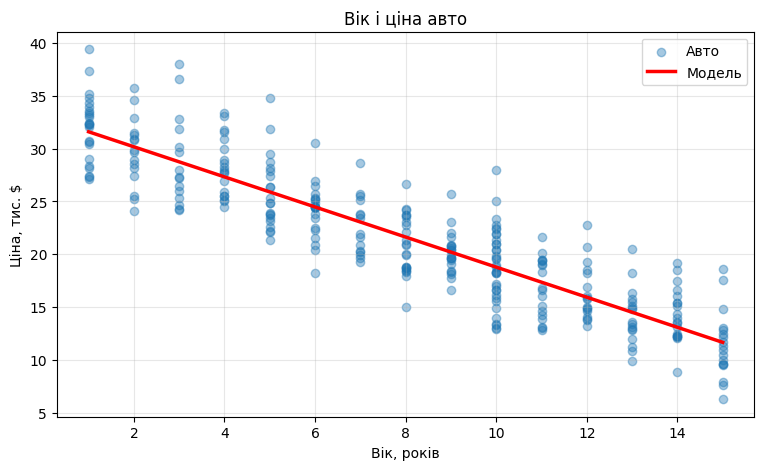

In [92]:
# line_x = pd.DataFrame({'age_years': [1, 15]})

# plt.scatter(cars['ВАШ_КОД'], cars['ВАШ_КОД'], alpha=0.4, label='Авто')
# plt.plot(line_x['age_years'], model_age.ВАШ_КОД(line_x), color='red', linewidth=2.5, label='Модель')
# plt.title('Вік і ціна авто')
# plt.xlabel('Вік, років')
# plt.ylabel('Ціна, тис. $')
# plt.legend()
# plt.show()

line_x = pd.DataFrame({'age_years': [1, 15]})
plt.scatter(cars['age_years'], cars['price'], alpha=0.4, label='Авто')
plt.plot(line_x['age_years'], model_age.predict(line_x), color='red', linewidth=2.5, label='Модель')
plt.title('Вік і ціна авто')
plt.xlabel('Вік, років')
plt.ylabel('Ціна, тис. $')
plt.legend()
plt.show()


### Завдання 4.5. Обмеження: прогноз для дуже старого авто

Спрогнозуйте ціну авто віком **30 років** (`pred_30`). Чи має результат сенс?

<details>
<summary><b>💡 Підказка 1</b></summary>

Так само, як у 4.3, тільки з віком 30.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
pred_30 = model_age.predict(pd.DataFrame({'age_years': [30]}))[0]
```

</details>

In [93]:
# pred_30 = model_age.predict(pd.DataFrame({'age_years': [ВАШ_КОД]}))[0]
# print(f'Прогноз для авто 30 років: {pred_30:.2f} тис. $')

pred_30 = model_age.predict(pd.DataFrame({'age_years': [30]}))[0]
print(f'Прогноз для авто 30 років: {pred_30:.2f} тис. $')


Прогноз для авто 30 років: -9.66 тис. $


In [94]:
check('4.5', pred_30)

✅ Завдання 4.5: правильно! Можна рухатися далі.


**✍️ Чому прогноз для 30-річного авто безглуздий? Яке правило звідси випливає?**

Прогнозована ціна 30-річного автомобіля становить −9.66 тис. $, що не має практичного сенсу, оскільки ціна автомобіля не може бути від'ємною.

Це демонструє обмеження лінійної регресії та проблему екстраполяції — прогнозування за межами діапазону даних, на яких навчалася модель.

---

## Блок 5. Метрики якості (⏱ 20 хв)

| Метрика | Функція | Як читати |
|---|---|---|
| MAE | `mean_absolute_error(y, y_pred)` | середня помилка в одиницях y; менше — краще |
| RMSE | `np.sqrt(mean_squared_error(y, y_pred))` | теж в одиницях y, сильніше «карає» великі помилки |
| R² | `r2_score(y, y_pred)` | частка розкиду y, яку пояснює модель: від 0 до 1, ближче до 1 — краще |

⚠️ У функціях метрик **спершу справжні значення**, потім прогнози.

### Завдання 5.1. MAE, RMSE і R² моделі за віком

Порахуйте прогнози моделі `model_age` для всіх авто і три метрики: `mae_all`, `rmse_all`, `r2_all`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Спершу `y_pred = model_age.predict(X)`, потім три функції метрик.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
y_pred = model_age.predict(X)
mae_all = mean_absolute_error(y, y_pred)
rmse_all = np.sqrt(mean_squared_error(y, y_pred))
r2_all = r2_score(y, y_pred)
```

</details>

In [95]:
# y_pred = model_age.predict(ВАШ_КОД)
# mae_all = mean_absolute_error(y, ВАШ_КОД)
# rmse_all = np.sqrt(mean_squared_error(y, y_pred))
# r2_all = ВАШ_КОД(y, y_pred)
# print(f'MAE = {mae_all:.2f} | RMSE = {rmse_all:.2f} | R² = {r2_all:.3f}')

y_pred = model_age.predict(X)
mae_all = mean_absolute_error(y, y_pred)
rmse_all = np.sqrt(mean_squared_error(y, y_pred))
r2_all = r2_score(y, y_pred)
print(f'MAE = {mae_all:.2f} | RMSE = {rmse_all:.2f} | R² = {r2_all:.3f}')


MAE = 2.38 | RMSE = 3.00 | R² = 0.800


In [96]:
check('5.1', mae_all, rmse_all, r2_all)

✅ Завдання 5.1: правильно! Можна рухатися далі.


Модель лінійної регресії за віком автомобіля має MAE = 2.38 тис. $, RMSE = 3.00 тис. $ та R² = 0.800.

Це означає, що модель пояснює приблизно 80% варіації цін автомобілів, а середня абсолютна помилка прогнозування становить 2.38 тис. $.

RMSE більша за MAE, що свідчить про сильніший вплив великих помилок на цю метрику.

Отже, модель досить добре описує залежність ціни від віку автомобіля на використаних даних.

### Завдання 5.2. R² і кореляція

Порахуйте кореляцію між віком і ціною (`r_age`) і її квадрат (`r_age_sq`). Порівняйте з `r2_all`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`cars['age_years'].corr(cars['price'])`, потім `** 2`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
r_age = cars['age_years'].corr(cars['price'])
r_age_sq = r_age ** 2
```

</details>

In [97]:
# r_age = cars['age_years'].corr(cars['ВАШ_КОД'])
# r_age_sq = r_age ** ВАШ_КОД
# print(f'r = {r_age:.3f} | r² = {r_age_sq:.3f} | R² моделі = {r2_all:.3f}')

r_age = cars['age_years'].corr(cars['price'])
r_age_sq = r_age ** 2
print(f'r = {r_age:.3f} | r² = {r_age_sq:.3f} | R² моделі = {r2_all:.3f}')


r = -0.895 | r² = 0.800 | R² моделі = 0.800


In [98]:
check('5.2', r_age, r_age_sq)

✅ Завдання 5.2: правильно! Можна рухатися далі.


### Завдання 5.3. Пояснюємо метрики менеджеру

Напишіть 2–3 речення для менеджера автомайданчика, який не знає статистики: наскільки точна модель за віком?

<details>
<summary><b>💡 Підказка 1</b></summary>

Використайте MAE («в середньому помиляємось на …») і R² («модель пояснює …% різниці в цінах»).

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Шаблон: «Якщо оцінювати ціну лише за віком авто, модель помиляється в середньому на … тис. $. Вік пояснює близько …% різниці в цінах; решта залежить від …»

</details>

In [99]:
# Розрахунки не потрібні — відповідь напишіть у клітинці нижче

**✍️ Пояснення для менеджера (2–3 речення):**

Модель досить добре прогнозує ціну автомобіля за його віком і пояснює приблизно 80% відмінностей між цінами в наявних даних.

У середньому прогнозована ціна відрізняється від фактичної приблизно на 2.38 тис. доларів.

Для оцінки точності прогнозів на нових автомобілях модель потрібно додатково перевірити на тестових даних.

---

## Блок 6. Навчальна і тестова вибірки (⏱ 30 хв)

**Чому не можна перевіряти модель на тих самих даних:** модель може «завчити» навчальні приклади разом з випадковим шумом (**перенавчання**). Тоді на знайомих даних вона виглядає чудово, а на нових працює погано. Як студент, що завчив відповіді на білети напам'ять.

**Рішення:** відкласти частину даних як **тестову** вибірку. Модель **не бачить** її під час навчання; оцінюємо якість саме на ній.

```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
```

- `test_size=0.2` — 20% даних іде в тест.
- `random_state=42` — фіксує випадкове розбиття, щоб у всіх вийшло однаково.
- Порядок результатів важливий: **X_train, X_test, y_train, y_test**.

### Завдання 6.1. Розбиваємо дані

Розбийте `X` (вік) і `y` на навчальну і тестову частини: 20% у тест, `random_state=42`. Збережіть кількість рядків у навчальній (`n_train`) і тестовій (`n_test`) частинах.

<details>
<summary><b>💡 Підказка 1</b></summary>

Функція повертає **чотири** результати. Кількість рядків — `len(...)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
n_train, n_test = len(X_train), len(X_test)
```

</details>

In [100]:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ВАШ_КОД, random_state=ВАШ_КОД)
# n_train = len(X_train)
# n_test = len(ВАШ_КОД)
# print('Train:', n_train, '| Test:', n_test)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
n_train = len(X_train)
n_test = len(X_test)
print('Train:', n_train, '| Test:', n_test)


Train: 240 | Test: 60


In [101]:
check('6.1', n_train, n_test)

✅ Завдання 6.1: правильно! Можна рухатися далі.


### Завдання 6.2. Навчаємо на train, оцінюємо на test

Навчіть нову модель **лише на навчальних даних** і порахуйте MAE на навчальних (`mae_train_1`) і на тестових (`mae_test_1`) даних.

<details>
<summary><b>💡 Підказка 1</b></summary>

`fit` — лише з `X_train, y_train`. Для MAE на тесті — прогнози для `X_test` порівнюємо з `y_test`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
model_tr = LinearRegression().fit(X_train, y_train)
mae_train_1 = mean_absolute_error(y_train, model_tr.predict(X_train))
mae_test_1 = mean_absolute_error(y_test, model_tr.predict(X_test))
```

</details>

In [102]:
# model_tr = LinearRegression()
# model_tr.fit(ВАШ_КОД, ВАШ_КОД)

# mae_train_1 = mean_absolute_error(y_train, model_tr.predict(X_train))
# mae_test_1 = mean_absolute_error(ВАШ_КОД, model_tr.predict(ВАШ_КОД))
# print(f'MAE train: {mae_train_1:.2f} | MAE test: {mae_test_1:.2f}')

model_tr = LinearRegression()
model_tr.fit(X_train, y_train)

mae_train_1 = mean_absolute_error(y_train, model_tr.predict(X_train))
mae_test_1 = mean_absolute_error(y_test, model_tr.predict(X_test))
print(f'MAE train: {mae_train_1:.2f} | MAE test: {mae_test_1:.2f}')


MAE train: 2.40 | MAE test: 2.33


In [103]:
check('6.2', mae_train_1, mae_test_1)

✅ Завдання 6.2: правильно! Можна рухатися далі.


**✍️ Помилки на train і test близькі. Про що це свідчить?**

Помилки на навчальних (MAE = 2.40 тис. $) і тестових (MAE = 2.33 тис. $) даних дуже близькі.

Це свідчить про те, що модель добре узагальнює дані та не має очевидних ознак перенавчання. Вона показує приблизно однакову точність на навчальній і тестовій вибірках.

### Завдання 6.3. Побачити перенавчання на власні очі

Візьміть лише **10 авто** для навчання (заготовку вже дано) і порівняйте дві моделі за пробігом: **пряму** (`deg=1`) і **криву 9-го степеня** (`deg=9`). Порахуйте MAE кожної на навчальних 10 авто і на решті («нових») авто. Збережіть MAE складної моделі в `mae_complex_train` і `mae_complex_new`.

<details>
<summary><b>💡 Підказка 1</b></summary>

`np.polyfit(x, y, deg=…)` підбирає криву потрібного степеня. Функція `mae_of(коефіцієнти, дані)` у заготовці вже рахує MAE. Вам треба лише вказати степені й викликати її.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
simple = np.polyfit(xs_small, small['price'], deg=1)
complex_ = np.polyfit(xs_small, small['price'], deg=9)
mae_complex_train = mae_of(complex_, small)
mae_complex_new = mae_of(complex_, rest)
```

</details>

Пряма:       train MAE = 2.20 | нові MAE = 2.61
9-й степінь: train MAE = 0.00 | нові MAE = 7.11


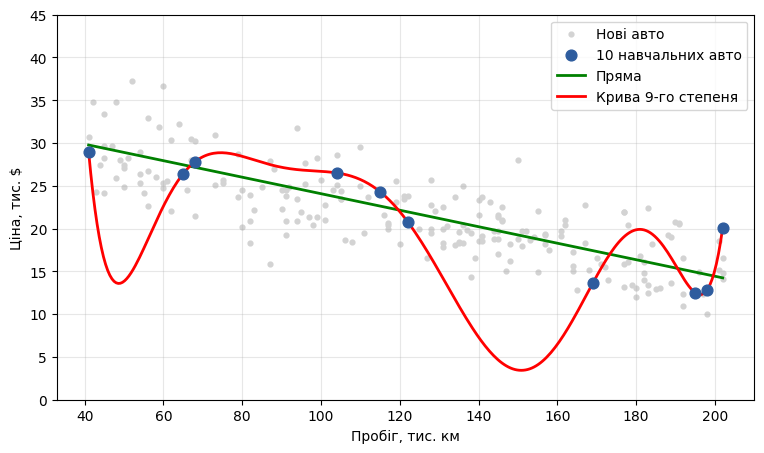

In [104]:
# small = cars.sample(10, random_state=9)                 # 10 авто для навчання
# rest = cars.drop(small.index)                           # «нові» авто
# rest = rest[(rest['mileage_th_km'] >= small['mileage_th_km'].min()) &
#             (rest['mileage_th_km'] <= small['mileage_th_km'].max())]
# xs_small = small['mileage_th_km'] / 100                 # масштабуємо для стабільності

# def mae_of(coefs, data):
#     return np.mean(np.abs(data['price'] - np.polyval(coefs, data['mileage_th_km'] / 100)))

# simple = np.polyfit(xs_small, small['price'], deg=ВАШ_КОД)
# complex_ = np.polyfit(xs_small, small['price'], deg=ВАШ_КОД)

# mae_complex_train = mae_of(complex_, ВАШ_КОД)
# mae_complex_new = mae_of(complex_, ВАШ_КОД)
# print(f'Пряма:       train MAE = {mae_of(simple, small):.2f} | нові MAE = {mae_of(simple, rest):.2f}')
# print(f'9-й степінь: train MAE = {mae_complex_train:.2f} | нові MAE = {mae_complex_new:.2f}')

# grid = np.linspace(small['mileage_th_km'].min(), small['mileage_th_km'].max(), 300)
# plt.scatter(rest['mileage_th_km'], rest['price'], color='lightgray', s=12, label='Нові авто')
# plt.scatter(small['mileage_th_km'], small['price'], color='#2E5C9E', s=60, zorder=3, label='10 навчальних авто')
# plt.plot(grid, np.polyval(simple, grid / 100), color='green', linewidth=2, label='Пряма')
# plt.plot(grid, np.polyval(complex_, grid / 100), color='red', linewidth=2, label='Крива 9-го степеня')
# plt.ylim(0, 45)
# plt.xlabel('Пробіг, тис. км')
# plt.ylabel('Ціна, тис. $')
# plt.legend()
# plt.show()

small = cars.sample(10, random_state=9)                 # 10 авто для навчання
rest = cars.drop(small.index)                           # «нові» авто
rest = rest[(rest['mileage_th_km'] >= small['mileage_th_km'].min()) &
            (rest['mileage_th_km'] <= small['mileage_th_km'].max())]
xs_small = small['mileage_th_km'] / 100

def mae_of(coefs, data):
    return np.mean(np.abs(data['price'] - np.polyval(coefs, data['mileage_th_km'] / 100)))

simple = np.polyfit(xs_small, small['price'], deg=1)
complex_ = np.polyfit(xs_small, small['price'], deg=9)

mae_complex_train = mae_of(complex_, small)
mae_complex_new = mae_of(complex_, rest)
print(f'Пряма:       train MAE = {mae_of(simple, small):.2f} | нові MAE = {mae_of(simple, rest):.2f}')
print(f'9-й степінь: train MAE = {mae_complex_train:.2f} | нові MAE = {mae_complex_new:.2f}')

grid = np.linspace(small['mileage_th_km'].min(), small['mileage_th_km'].max(), 300)
plt.scatter(rest['mileage_th_km'], rest['price'], color='lightgray', s=12, label='Нові авто')
plt.scatter(small['mileage_th_km'], small['price'], color='#2E5C9E', s=60, zorder=3, label='10 навчальних авто')
plt.plot(grid, np.polyval(simple, grid / 100), color='green', linewidth=2, label='Пряма')
plt.plot(grid, np.polyval(complex_, grid / 100), color='red', linewidth=2, label='Крива 9-го степеня')
plt.ylim(0, 45)
plt.xlabel('Пробіг, тис. км')
plt.ylabel('Ціна, тис. $')
plt.legend()
plt.show()


In [105]:
check('6.3', mae_complex_train, mae_complex_new)

✅ Завдання 6.3: правильно! Можна рухатися далі.


**✍️ Яку модель ви б обрали, якби дивилися лише на навчальні дані? А якщо на нові? Що з цього випливає?**

Якщо оцінювати моделі лише на навчальних даних, я б обрала модель 9-го степеня, оскільки її MAE = 0.00.

Однак на нових даних кращою є лінійна модель (MAE = 2.61 проти 7.11).

Це демонструє перенавчання (overfitting): складна модель запам'ятала навчальні дані, але погано узагальнює їх для нових автомобілів.

### Завдання 6.4. Тест як «запечатаний конверт» ⭐ *бонус*

Колега каже: «Я спробував 50 різних моделей, для кожної дивився MAE на тестовій вибірці, і обрав ту, де він найменший. Отже, моя модель на нових даних матиме саме такий MAE». Чи має він рацію? Оберіть відповідь.

- **а)** так, тестовий MAE — завжди чесна оцінка
- **б)** ні: він «підігнав» вибір моделі під тестові дані, тож на справді нових даних помилка, найімовірніше, буде більшою
- **в)** ні, бо MAE взагалі не підходить для регресії

<details>
<summary><b>💡 Підказка 1</b></summary>

Якщо тестові дані багато разів використовувати для вибору, вони перестають бути «новими» для всього процесу.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Це як вибрати з 50 студентів того, хто випадково найкраще написав конкретний тест: на наступному тесті він, найімовірніше, покаже скромніший результат.

</details>

In [106]:
# answer_6_4 = 'ВАШ_КОД'
answer_6_4 = 'b'


In [107]:
check('6.4', answer_6_4)

✅ Завдання 6.4: правильно! Можна рухатися далі.


---

## Блок 7. Кілька ознак (⏱ 30 хв)

Модель з кількома ознаками:

$$\text{ціна} = a + b_1 \cdot \text{вік} + b_2 \cdot \text{пробіг} + b_3 \cdot \text{двигун}$$

**У коді змінюється лише список стовпців у X** — усе інше так само.

**Як читати коефіцієнти:** «на скільки зміниться прогноз, якщо ця ознака зросте на 1, **а всі інші залишаться такими самими**» («за інших рівних»).

### Завдання 7.1. Модель з трьома ознаками

Створіть X з трьох ознак: `age_years`, `mileage_th_km`, `engine_l`. Розбийте на train/test (`test_size=0.2, random_state=42`), навчіть модель на train. Збережіть коефіцієнти (`coefs_3` — масив із 3 чисел).

<details>
<summary><b>💡 Підказка 1</b></summary>

Список ознак — у подвійних дужках: `cars[features]`, де `features` — список назв. Розбиття і навчання — як у блоці 6.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
features = ['age_years', 'mileage_th_km', 'engine_l']
X3 = cars[features]
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y, test_size=0.2, random_state=42)
model_3 = LinearRegression().fit(X3_train, y3_train)
coefs_3 = model_3.coef_
```

</details>

In [108]:
# features = ['age_years', 'ВАШ_КОД', 'ВАШ_КОД']
# X3 = cars[features]
# X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y, test_size=0.2, random_state=42)

# model_3 = LinearRegression()
# model_3.fit(ВАШ_КОД, ВАШ_КОД)
# coefs_3 = model_3.coef_

# for name, c in zip(features, coefs_3):
#     print(f'{name:14}: {c:+.3f}')
# print(f'intercept     : {model_3.intercept_:+.2f}')

features = ['age_years', 'mileage_th_km', 'engine_l']
X3 = cars[features]
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y, test_size=0.2, random_state=42)

model_3 = LinearRegression()
model_3.fit(X3_train, y3_train)
coefs_3 = model_3.coef_

for name, c in zip(features, coefs_3):
    print(f'{name:14}: {c:+.3f}')
print(f'intercept     : {model_3.intercept_:+.2f}')


age_years     : -0.914
mileage_th_km : -0.034
engine_l      : +4.455
intercept     : +25.20


In [109]:
check('7.1', coefs_3)

✅ Завдання 7.1: правильно! Можна рухатися далі.


### Завдання 7.2. Чи стала модель кращою?

Порахуйте MAE (`mae_test_3`) і R² (`r2_test_3`) моделі з трьома ознаками **на тестових даних** і порівняйте з моделлю лише за віком (`mae_test_1` з 6.2).

<details>
<summary><b>💡 Підказка 1</b></summary>

Прогнози для `X3_test` порівнюємо з `y3_test`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
mae_test_3 = mean_absolute_error(y3_test, model_3.predict(X3_test))
r2_test_3 = r2_score(y3_test, model_3.predict(X3_test))
```

</details>

In [110]:
# mae_test_3 = mean_absolute_error(ВАШ_КОД, model_3.predict(ВАШ_КОД))
# r2_test_3 = r2_score(y3_test, model_3.predict(X3_test))
# print(f'MAE на тесті: 1 ознака = {mae_test_1:.2f} | 3 ознаки = {mae_test_3:.2f}')
# print(f'R² на тесті (3 ознаки) = {r2_test_3:.3f}')

mae_test_3 = mean_absolute_error(y3_test, model_3.predict(X3_test))
r2_test_3 = r2_score(y3_test, model_3.predict(X3_test))
print(f'MAE на тесті: 1 ознака = {mae_test_1:.2f} | 3 ознаки = {mae_test_3:.2f}')
print(f'R² на тесті (3 ознаки) = {r2_test_3:.3f}')


MAE на тесті: 1 ознака = 2.33 | 3 ознаки = 1.47
R² на тесті (3 ознаки) = 0.940


In [111]:
check('7.2', mae_test_3, r2_test_3)

✅ Завдання 7.2: правильно! Можна рухатися далі.


### Завдання 7.3. Оцінка конкретного авто

Клієнт продає авто: **4 роки, пробіг 60 тис. км, двигун 2.0 л**. Яку ціну прогнозує модель з трьома ознаками? Збережіть у `pred_car`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Створіть таблицю з **тими самими** назвами стовпців і в **тому самому** порядку, що й під час навчання.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
car = pd.DataFrame({'age_years': [4], 'mileage_th_km': [60], 'engine_l': [2.0]})
pred_car = model_3.predict(car)[0]
```

</details>

In [112]:
# car = pd.DataFrame({'age_years': [ВАШ_КОД], 'mileage_th_km': [ВАШ_КОД], 'engine_l': [ВАШ_КОД]})
# pred_car = model_3.predict(car)[0]
# print(f'Прогнозна ціна: {pred_car:.2f} тис. $')

car = pd.DataFrame({'age_years': [4], 'mileage_th_km': [60], 'engine_l': [2.0]})
pred_car = model_3.predict(car)[0]
print(f'Прогнозна ціна: {pred_car:.2f} тис. $')


Прогнозна ціна: 28.44 тис. $


In [113]:
check('7.3', pred_car)

✅ Завдання 7.3: правильно! Можна рухатися далі.


### Завдання 7.4. Як читати коефіцієнти

Подивіться на коефіцієнти з 7.1 і дайте відповідь на питання нижче.

<details>
<summary><b>💡 Підказка 1</b></summary>

Пам'ятайте про «за інших рівних». Пробіг вимірюється в тисячах км.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Коефіцієнт пробігу показує зміну ціни на **1 тис. км**. Щоб отримати зміну на 10 тис. км, помножте його на 10.

</details>

In [114]:
# Розрахунки за бажанням: наприклад, як зміниться ціна при +10 тис. км пробігу
print(f'+10 тис. км: {coefs_3[1] * 10:+.2f} тис. $')

+10 тис. км: -0.34 тис. $


**✍️ Поясніть кожен з трьох коефіцієнтів одним реченням. Чому коефіцієнт віку тут менший за модулем, ніж у моделі лише з віком (блок 4)?**

**1. Вік автомобіля (−0.914):** зі збільшенням віку на 1 рік прогнозована ціна зменшується приблизно на 0.914 тис. $ за незмінних пробігу та об'єму двигуна.

**2. Пробіг (−0.034):** зі збільшенням пробігу на 1 тис. км прогнозована ціна зменшується приблизно на 0.034 тис. $ (34 $) за інших рівних умов.

**3. Об'єм двигуна (+4.455):** зі збільшенням об'єму двигуна на 1 літр прогнозована ціна зростає приблизно на 4.455 тис. $ за інших рівних умов.

Коефіцієнт віку став меншим за модулем (−0.914 замість −1.422), оскільки модель тепер окремо враховує пробіг та об'єм двигуна. У попередній моделі вік частково відображав також вплив пробігу, адже старіші автомобілі зазвичай мають більший пробіг.

### Завдання 7.5. А якщо додати непотрібну ознаку? ⭐ *бонус*

Додайте до трьох ознак кількість дверей (`doors`), навчіть модель на тому ж розбитті. Збережіть коефіцієнт дверей (`coef_doors`) і MAE на тесті (`mae_test_4`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Список з 4 ознак, потім той самий `train_test_split` з `random_state=42`. Коефіцієнт дверей — останній у `coef_`, тобто `coef_[-1]`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
features_4 = ['age_years', 'mileage_th_km', 'engine_l', 'doors']
X4_train, X4_test, y4_train, y4_test = train_test_split(cars[features_4], y, test_size=0.2, random_state=42)
model_4 = LinearRegression().fit(X4_train, y4_train)
coef_doors = model_4.coef_[-1]
mae_test_4 = mean_absolute_error(y4_test, model_4.predict(X4_test))
```

</details>

In [115]:
# features_4 = ['age_years', 'mileage_th_km', 'engine_l', 'ВАШ_КОД']
# X4_train, X4_test, y4_train, y4_test = train_test_split(cars[features_4], y, test_size=0.2, random_state=42)
# model_4 = LinearRegression().fit(X4_train, y4_train)

# coef_doors = model_4.coef_[ВАШ_КОД]
# mae_test_4 = mean_absolute_error(y4_test, model_4.predict(ВАШ_КОД))
# print(f'Коефіцієнт дверей: {coef_doors:+.3f}')
# print(f'MAE на тесті: 3 ознаки = {mae_test_3:.3f} | 4 ознаки = {mae_test_4:.3f}')

# Вибираємо 4 ознаки автомобіля, включно з кількістю дверей
features_4 = ['age_years', 'mileage_th_km', 'engine_l', 'doors']

# Розділяємо дані: 80% для навчання, 20% для тестування
X4_train, X4_test, y4_train, y4_test = train_test_split(
    cars[features_4], y, test_size=0.2, random_state=42
)

# Створюємо та навчаємо модель із 4 ознаками
model_4 = LinearRegression().fit(X4_train, y4_train)

# Отримуємо коефіцієнт кількості дверей
# Індекс [3], оскільки doors — четверта ознака (нумерація з нуля)
coef_doors = model_4.coef_[3]

# Обчислюємо MAE на тестових даних
mae_test_4 = mean_absolute_error(
    y4_test, model_4.predict(X4_test)
)

# Виводимо результати
print(f'Коефіцієнт дверей: {coef_doors:.3f}')
print(f'MAE на тесті: 3 ознаки = {mae_test_3:.3f} | 4 ознаки = {mae_test_4:.3f}')

Коефіцієнт дверей: 0.156
MAE на тесті: 3 ознаки = 1.470 | 4 ознаки = 1.461


In [116]:
check('7.5', coef_doors, mae_test_4)

✅ Завдання 7.5: правильно! Можна рухатися далі.


Після додавання кількості дверей коефіцієнт цієї ознаки становить +0.156, а тестова MAE зменшилася з 1.470 до 1.461 тис. $.

Покращення становить лише 0.009 тис. $ (9 $), тому додавання кількості дверей майже не вплинуло на точність прогнозування.

Отже, ця ознака має невелику додаткову користь для моделі на використаних даних, і її можна не включати, щоб зберегти модель простішою.

---

## Блок 8. Підсумкове завдання: звіт для автомайданчика (⏱ 15 хв)

Керівник онлайн-майданчика хоче додати на сайт кнопку «Оцінити моє авто». Він питає: **«Наскільки точно модель може оцінити ціну і від чого вона найбільше залежить?»**

### Завдання 8.1. Звіт для керівника

Напишіть звіт з 5–7 речень простою мовою. У ньому має бути:

1. яку модель ви побудували і за якими ознаками;
2. як її перевіряли (чому окрема тестова вибірка);
3. наскільки вона точна (MAE і R² на тесті);
4. як кожна ознака впливає на ціну;
5. обмеження: коли модель не варто використовувати.

<details>
<summary><b>💡 Підказка 1</b></summary>

Перегляньте результати блоків 6 і 7. Числа можна вивести ще раз у клітинці нижче.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Шаблон: «Ми побудували лінійну регресію, яка оцінює ціну за … . Щоб перевірка була чесною, …% авто ми відклали і модель їх не бачила. На цих авто модель помиляється в середньому на … тис. $ і пояснює …% різниці в цінах. Найсильніше на ціну впливають … . Модель не варто використовувати для …»

</details>

In [117]:
# Виведіть потрібні числа
print(f'MAE на тесті: {mae_test_3:.2f}, R²: {r2_test_3:.3f}')
print(dict(zip(features, coefs_3.round(3))))

MAE на тесті: 1.47, R²: 0.940
{'age_years': np.float64(-0.914), 'mileage_th_km': np.float64(-0.034), 'engine_l': np.float64(4.455)}


**✍️ Звіт для керівника (5–7 речень):**

Ми побудували модель лінійної регресії, яка прогнозує ціну автомобіля за його віком, пробігом та об'ємом двигуна.

Модель навчали на 80% автомобілів, а її точність перевірили на решті 20% даних, які не використовувалися для навчання.

На тестових даних середня абсолютна помилка прогнозу (MAE) становить 1.47 тис. $, а R² = 0.940, тобто модель пояснює приблизно 94% варіації цін.

За інших рівних умов кожен додатковий рік віку знижує прогнозовану ціну приблизно на 0.914 тис. $, кожні 10 тис. км пробігу — на 0.34 тис. $, а збільшення об'єму двигуна на 1 літр підвищує її приблизно на 4.455 тис. $.

Найважливішими для прогнозування є вік, пробіг та об'єм двигуна, тоді як додавання кількості дверей майже не покращило точність моделі.

Модель можна розглядати як основу для попередньої оцінки автомобілів, але її прогнози можуть бути ненадійними для автомобілів із характеристиками, що виходять за межі навчальних даних.

---
## 🎉 Готово!

Ви пройшли весь шлях першої ML-моделі: від прямої «на око» до лінійної регресії з кількома ознаками, перевіреної на тестових даних.

**Перед здачею:** *Runtime → Restart and run all* (у Colab) — переконайтеся, що весь блокнот запускається зверху вниз без помилок.